In [24]:
import pandas as pd
df = pd.read_csv("us-employment.csv", parse_dates=["month"])
print(df.shape)
print(df.head())

(120, 24)
       month  nonfarm  private  goods_producing  service_providing  \
0 2006-01-01   135450   113603            22467             112983   
1 2006-02-01   135762   113884            22535             113227   
2 2006-03-01   136059   114156            22572             113487   
3 2006-04-01   136227   114308            22631             113596   
4 2006-05-01   136258   114332            22597             113661   

   private_service_providing  mining_and_logging  construction  manufacturing  \
0                      91136                 656          7601          14210   
1                      91349                 662          7664          14209   
2                      91584                 669          7689          14214   
3                      91677                 679          7726          14226   
4                      91735                 681          7713          14203   

   durable_goods  ...  transportation_and_warehousing  utilities  information  \
0

In [25]:
df["target"]=(df["nonfarm_change"].shift(-1)>0).astype(int)

In [26]:
print(df[["month", "nonfarm_change", "target"]].head())

       month  nonfarm_change  target
0 2006-01-01             282       1
1 2006-02-01             312       1
2 2006-03-01             297       1
3 2006-04-01             168       1
4 2006-05-01              31       1


In [27]:
print(df[["month", "nonfarm", "nonfarm_change"]].head(10))

       month  nonfarm  nonfarm_change
0 2006-01-01   135450             282
1 2006-02-01   135762             312
2 2006-03-01   136059             297
3 2006-04-01   136227             168
4 2006-05-01   136258              31
5 2006-06-01   136337              79
6 2006-07-01   136543             206
7 2006-08-01   136722             179
8 2006-09-01   136870             148
9 2006-10-01   136882              12


In [28]:
sectors=[
    'mining_and_logging', 'construction', 'manufacturing', 'trade_transportation_utilties', 'information', 'financial_activities', 'professional_and_business_services', 'education_and_health_services', 'leisure_and_hospitality', 'other_services', 'government'
]
x=df[sectors].diff()
x.columns = [c + '_chg' for c in sectors]


In [29]:
data = pd.concat([df[['month', 'target']], x], axis=1)
data = data.iloc[1:-1].reset_index(drop=True)

In [30]:
print(data.shape)
print(data['target'].value_counts(normalize=True))
print(data.head())

(118, 13)
target
1    0.754237
0    0.245763
Name: proportion, dtype: float64
       month  target  mining_and_logging_chg  construction_chg  \
0 2006-02-01       1                     6.0              63.0   
1 2006-03-01       1                     7.0              25.0   
2 2006-04-01       1                    10.0              37.0   
3 2006-05-01       1                     2.0             -13.0   
4 2006-06-01       1                     5.0             -14.0   

   manufacturing_chg  trade_transportation_utilties_chg  information_chg  \
0               -1.0                               34.0              0.0   
1                5.0                               43.0              3.0   
2               12.0                               -9.0             -9.0   
3              -23.0                               -7.0             -7.0   
4               10.0                               18.0             -3.0   

   financial_activities_chg  professional_and_business_services_chg 

In [31]:
train = data[data['month'] < '2009-01-01']
test = data[data['month'] >= '2009-01-01']

In [32]:
feature_cols = [c for c in data.columns if c.endswith('_chg')]

In [33]:
x_train, y_train = train[feature_cols], train['target']
x_test, y_test = test[feature_cols], test['target']

In [34]:
print(len(train), len(test))
print(y_train.value_counts())
print(y_test.value_counts())

35 83
target
1    21
0    14
Name: count, dtype: int64
target
1    68
0    15
Name: count, dtype: int64


In [35]:
baseline_acc = (y_test==1).mean()
print('Baseline accuracy', baseline_acc)

Baseline accuracy 0.8192771084337349


In [36]:
down = data[data["target"] == 0]
print(down["month"].dt.strftime("%Y-%m").tolist())
print(down["month"].min(), down["month"].max())

['2007-06', '2007-07', '2008-01', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06', '2008-07', '2008-08', '2008-09', '2008-10', '2008-11', '2008-12', '2009-01', '2009-02', '2009-03', '2009-04', '2009-05', '2009-06', '2009-07', '2009-08', '2009-09', '2009-11', '2010-01', '2010-05', '2010-06', '2010-07', '2010-08']
2007-06-01 00:00:00 2010-08-01 00:00:00


In [37]:
print(df[df["nonfarm_change"] < 0]["month"].dt.strftime("%Y-%m").tolist())

['2007-07', '2007-08', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06', '2008-07', '2008-08', '2008-09', '2008-10', '2008-11', '2008-12', '2009-01', '2009-02', '2009-03', '2009-04', '2009-05', '2009-06', '2009-07', '2009-08', '2009-09', '2009-10', '2009-12', '2010-02', '2010-06', '2010-07', '2010-08', '2010-09']


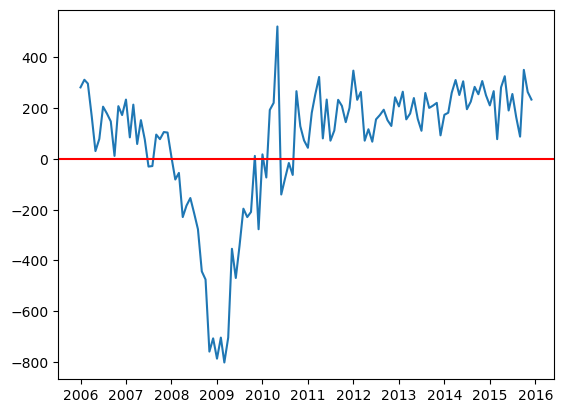

In [38]:
import matplotlib.pyplot as plt
plt.plot(df["month"], df["nonfarm_change"])
plt.axhline(0, color="red")
plt.show()

In [39]:
tr = train.copy()
tr['prof_fell'] = tr['professional_and_business_services_chg'] < 0
print(pd.crosstab(tr['prof_fell'], tr['target']))

target      0   1
prof_fell        
False       2  19
True       12   2


In [40]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
nb = GaussianNB()
nb.fit(x_train, y_train)
pred = nb.predict(x_test)
print('Accuracy', accuracy_score(y_test, pred))
print('Baseline accuracy', baseline_acc)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))  

Accuracy 0.8674698795180723
Baseline accuracy 0.8192771084337349
[[13  2]
 [ 9 59]]
              precision    recall  f1-score   support

           0       0.59      0.87      0.70        15
           1       0.97      0.87      0.91        68

    accuracy                           0.87        83
   macro avg       0.78      0.87      0.81        83
weighted avg       0.90      0.87      0.88        83



In [41]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
tree = DecisionTreeClassifier(max_depth=3, random_state=42)   
tree.fit (x_train, y_train)
pred_tree = tree.predict(x_test)


In [42]:
print('Accuracy', accuracy_score(y_test, pred_tree))
print(confusion_matrix(y_test, pred_tree)) 


Accuracy 0.9036144578313253
[[ 8  7]
 [ 1 67]]


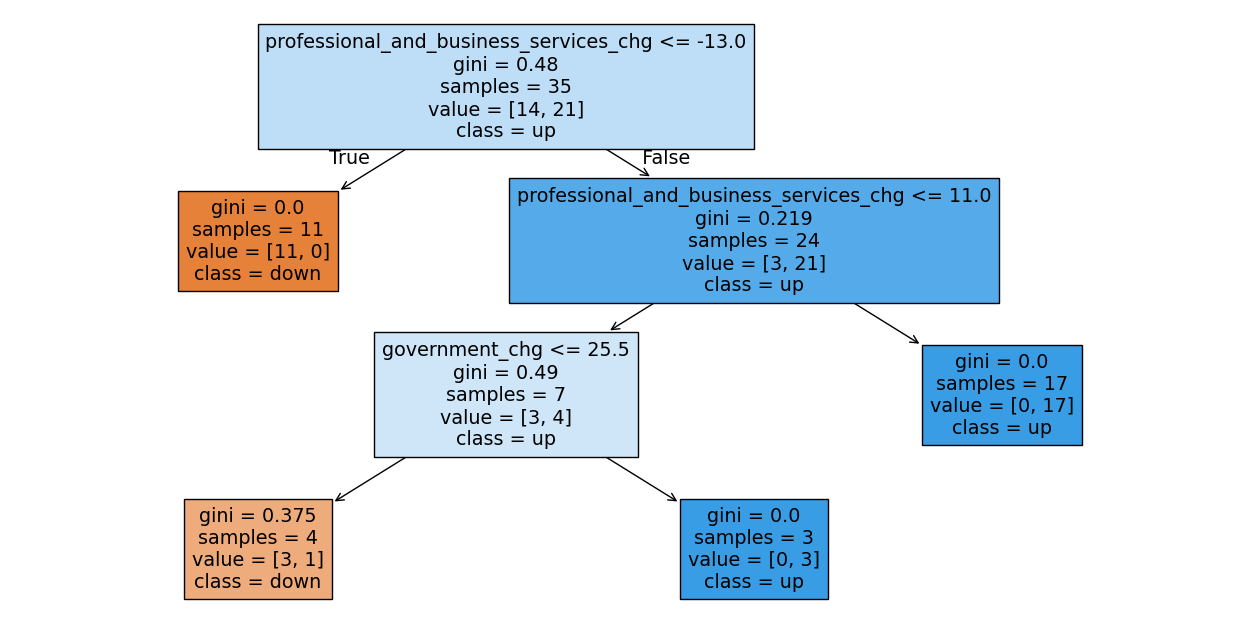

In [43]:
plt.figure(figsize=(16,8))
plot_tree(tree, feature_names=feature_cols, class_names=["down", "up"], filled=True)
plt.show()

In [44]:
import numpy as np
from sklearn.metrics import recall_score, precision_score
always_up = np.ones(len(y_test), dtype=int)
models = {"Always up": always_up, "Naive Bayes": pred, "Decision tree": pred_tree}

In [45]:
rows = []
for name, p in models.items():
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, p),
        "falls caught": recall_score(y_test, p, pos_label=0),
        "warnings correct": precision_score(y_test, p, pos_label=0, zero_division=0)
    })

print(pd.DataFrame(rows).round(2))


           model  accuracy  falls caught  warnings correct
0      Always up      0.82          0.00              0.00
1    Naive Bayes      0.87          0.87              0.59
2  Decision tree      0.90          0.53              0.89


In [46]:
for d in [1, 2, 3, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    t.fit(x_train, y_train)
    print(d, round(t.score(x_train, y_train), 3), round(t.score(x_test, y_test), 3))

1 0.914 0.916
2 0.914 0.916
3 0.971 0.904
None 1.0 0.904
